# Notebook 00 - Data Exploration & Engineering Reference

This notebook explores the raw dataset, validates column availability, and documents the **revenue engineering strategy** used across all model notebooks.

---
**Dataset**: Instacart-style grocery orders  
**Purpose**: Understand data before modelling, shared reference for all ML notebooks

In [2]:
# What: Import data analysis and visualization libraries
# Why: Need pandas/numpy for manipulation, matplotlib/seaborn for plots
# Method: Standard scientific Python stack
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
import os
import warnings
warnings.filterwarnings('ignore')

# Set consistent plot style
plt.style.use('seaborn-v0_8-darkgrid')
plt.rcParams['figure.figsize'] = (12, 5)
plt.rcParams['font.size'] = 12

DATA_PATH = '../data'
print('Libraries loaded')

Libraries loaded


In [3]:
# What: Load all dataset CSV files
# Why: Get a full picture of the available data before modelling
# Method: pandas.read_csv with shape report after each load
orders       = pd.read_csv(f'{DATA_PATH}/orders.csv')
products     = pd.read_csv(f'{DATA_PATH}/products.csv')
departments  = pd.read_csv(f'{DATA_PATH}/departments.csv')
aisles       = pd.read_csv(f'{DATA_PATH}/aisles.csv')
op_train     = pd.read_csv(f'{DATA_PATH}/order_products__train.csv')

print('Dataset sizes:')
print(f'  orders              : {orders.shape}')
print(f'  products            : {products.shape}')
print(f'  departments         : {departments.shape}')
print(f'  aisles              : {aisles.shape}')
print(f'  order_products_train: {op_train.shape}')

Dataset sizes:
  orders              : (3421083, 7)
  products            : (49688, 4)
  departments         : (21, 2)
  aisles              : (134, 2)
  order_products_train: (1384617, 4)


In [4]:
# What: Show column names and dtypes for every file
# Why: Confirm what features are available for modelling
# Method: Iterate over each dataframe and print info
for name, df in [('orders', orders), ('products', products),
                 ('departments', departments), ('aisles', aisles),
                 ('op_train', op_train)]:
    print(f'\n=== {name} ===')
    print(df.dtypes.to_string())


=== orders ===
order_id                    int64
user_id                     int64
eval_set                      str
order_number                int64
order_dow                   int64
order_hour_of_day           int64
days_since_prior_order    float64

=== products ===
product_id       int64
product_name       str
aisle_id         int64
department_id    int64

=== departments ===
department_id    int64
department         str

=== aisles ===
aisle_id    int64
aisle         str

=== op_train ===
order_id             int64
product_id           int64
add_to_cart_order    int64
reordered            int64


In [5]:
# What: Check missing values in orders (the core table)
# Why: days_since_prior_order is NaN for first order per user — need to handle
# Method: isnull().sum() report
print('Missing values in orders:')
print(orders.isnull().sum())
print(f'\nNull days_since_prior_order = first order per user ({orders["days_since_prior_order"].isnull().sum():,} rows)')
print(f'Total unique users: {orders["user_id"].nunique():,}')
print(f'Total unique orders: {orders["order_id"].nunique():,}')

Missing values in orders:
order_id                       0
user_id                        0
eval_set                       0
order_number                   0
order_dow                      0
order_hour_of_day              0
days_since_prior_order    206209
dtype: int64

Null days_since_prior_order = first order per user (206,209 rows)
Total unique users: 206,209
Total unique orders: 3,421,083


In [6]:
# What: Show eval_set split breakdown
# Why: Understand which orders are for training, prior history, or test
# Method: value_counts on eval_set column
print('eval_set distribution:')
print(orders['eval_set'].value_counts())

eval_set distribution:
eval_set
prior    3214874
train     131209
test       75000
Name: count, dtype: int64


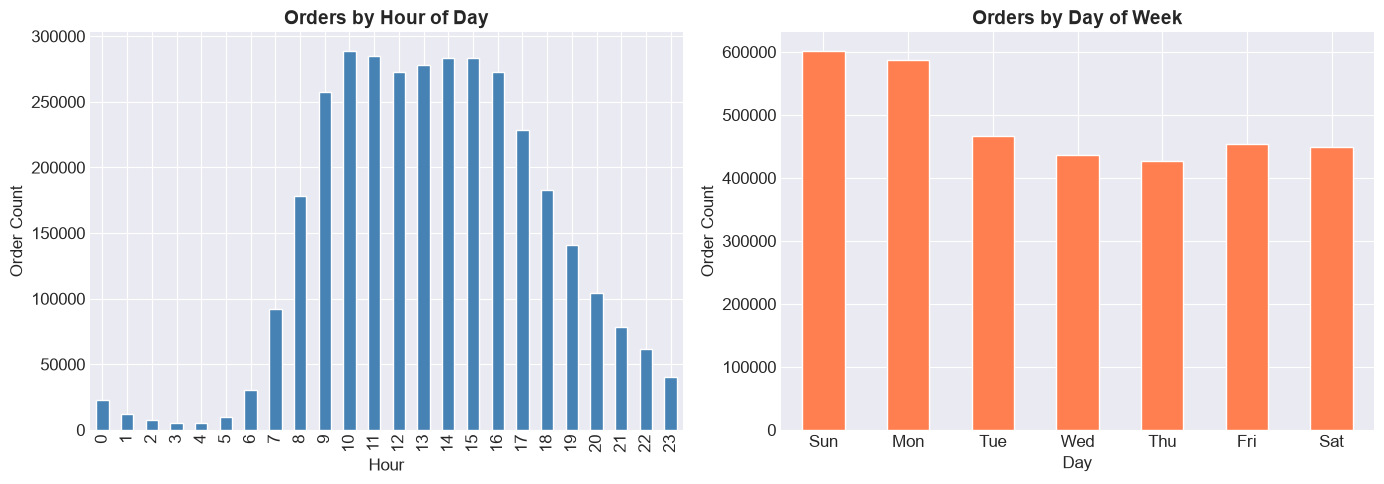

Plot saved


In [18]:
# What: Visualize order hour and day-of-week patterns
# Why: Understand when users shop — key feature for daily revenue models
# Method: Two side-by-side bar charts
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Orders by hour of day
orders['order_hour_of_day'].value_counts().sort_index().plot(
    kind='bar', ax=axes[0], color='steelblue', edgecolor='white')
axes[0].set_title('Orders by Hour of Day', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Hour')
axes[0].set_ylabel('Order Count')

# Orders by day of week
dow_labels = ['Sun', 'Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat']
orders['order_dow'].value_counts().sort_index().plot(
    kind='bar', ax=axes[1], color='coral', edgecolor='white')
axes[1].set_xticklabels(dow_labels, rotation=0)
axes[1].set_title('Orders by Day of Week', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Day')
axes[1].set_ylabel('Order Count')

plt.tight_layout()
plt.savefig('../models/eda_order_patterns.png', dpi=150, bbox_inches='tight')
plt.show()
print('Plot saved')

In [8]:
# What: Show department list — used for price mapping in revenue engineering
# Why: Revenue proxy depends on correct department assignment
# Method: Print full departments table
print('All departments (used for revenue proxy pricing):')
print(departments.to_string(index=False))

All departments (used for revenue proxy pricing):
 department_id      department
             1          frozen
             2           other
             3          bakery
             4         produce
             5         alcohol
             6   international
             7       beverages
             8            pets
             9 dry goods pasta
            10            bulk
            11   personal care
            12    meat seafood
            13          pantry
            14       breakfast
            15    canned goods
            16      dairy eggs
            17       household
            18          babies
            19          snacks
            20            deli
            21         missing


In [17]:
# What: Define and validate department price mapping (Rs.)
# Why: No price column in dataset; revenue must be engineered
# Method: Manually assigned avg prices per department category, realistic for a Sri Lankan grocery shop
DEPT_PRICE = {
    1:  350,  # frozen      — frozen meals avg
    2:  200,  # other
    3:  250,  # bakery      — bread, cakes
    4:  150,  # produce     — vegetables, fruits
    5:  800,  # alcohol     — beer, wine
    6:  400,  # international
    7:  180,  # beverages   — juices, soft drinks
    8:  600,  # pets        — pet food, accessories
    9:  300,  # dry goods pasta
    10: 200,  # bulk
    11: 500,  # personal care
    12: 700,  # meat seafood
    13: 350,  # pantry
    14: 280,  # breakfast   — cereals, oats
    15: 200,  # canned goods
    16: 300,  # dairy eggs
    17: 450,  # household
    18: 500,  # babies
    19: 220,  # snacks
    20: 400,  # deli
    21: 200,  # missing
}
print('Price mapping defined for', len(DEPT_PRICE), 'departments')
price_df = pd.DataFrame(list(DEPT_PRICE.items()), columns=['department_id','avg_price_rs'])
price_df = price_df.merge(departments, on='department_id')
print(price_df[['department_id','department','avg_price_rs']].to_string(index=False))

Price mapping defined for 21 departments
 department_id      department  avg_price_rs
             1          frozen           350
             2           other           200
             3          bakery           250
             4         produce           150
             5         alcohol           800
             6   international           400
             7       beverages           180
             8            pets           600
             9 dry goods pasta           300
            10            bulk           200
            11   personal care           500
            12    meat seafood           700
            13          pantry           350
            14       breakfast           280
            15    canned goods           200
            16      dairy eggs           300
            17       household           450
            18          babies           500
            19          snacks           220
            20            deli           400
            21

In [10]:
# What: Build enriched order-item table with revenue proxy
# Why: Demonstrate the core feature engineering pipeline used in all model notebooks
# Method: Merge op_train → products → departments → orders, then assign price
products_dept = products.merge(departments, on='department_id', how='left')
order_items = op_train.merge(products_dept[['product_id','department_id']], on='product_id', how='left')
order_items = order_items.merge(
    orders[['order_id','user_id','order_number','order_dow','order_hour_of_day','days_since_prior_order']],
    on='order_id', how='left'
)
order_items['price'] = order_items['department_id'].map(DEPT_PRICE).fillna(200)
order_items['revenue'] = order_items['price']  # 1 unit per cart addition
print('Enriched order items shape:', order_items.shape)
print(order_items[['order_id','product_id','department_id','price','revenue','order_dow']].head(8))

Enriched order items shape: (1384617, 12)
   order_id  product_id  department_id  price  revenue  order_dow
0         1       49302             16    300      300          4
1         1       11109             16    300      300          4
2         1       10246              4    150      150          4
3         1       49683              4    150      150          4
4         1       43633             15    200      200          4
5         1       13176              4    150      150          4
6         1       47209              4    150      150          4
7         1       22035             16    300      300          4


In [11]:
# What: Demonstrate month simulation from order_number
# Why: Dataset has no dates; order_number is the only temporal signal
# Method: month_num = ceil(order_number / 3) — 3 orders ≈ 1 month at avg 11 days/order
order_items['month_num'] = np.ceil(order_items['order_number'] / 3).astype(int)
monthly_summary = order_items.groupby('month_num').agg(
    total_revenue=('revenue', 'sum'),
    total_orders=('order_id', 'nunique'),
    unique_users=('user_id', 'nunique'),
    total_items=('product_id', 'count')
).reset_index()
print('Monthly summary (first 10 months):')
print(monthly_summary.head(10).to_string(index=False))

Monthly summary (first 10 months):
 month_num  total_revenue  total_orders  unique_users  total_items
         2      101157820         38076         38076       378758
         3       62519220         22682         22682       234960
         4       42314000         15089         15089       159565
         5       30729680         10804         10804       116496
         6       22744060          7989          7989        86036
         7       17324750          6074          6074        65762
         8       13948660          4815          4815        53461
         9       11383630          3948          3948        43543
        10        9227630          3143          3143        35283
        11        7785210          2603          2603        29879


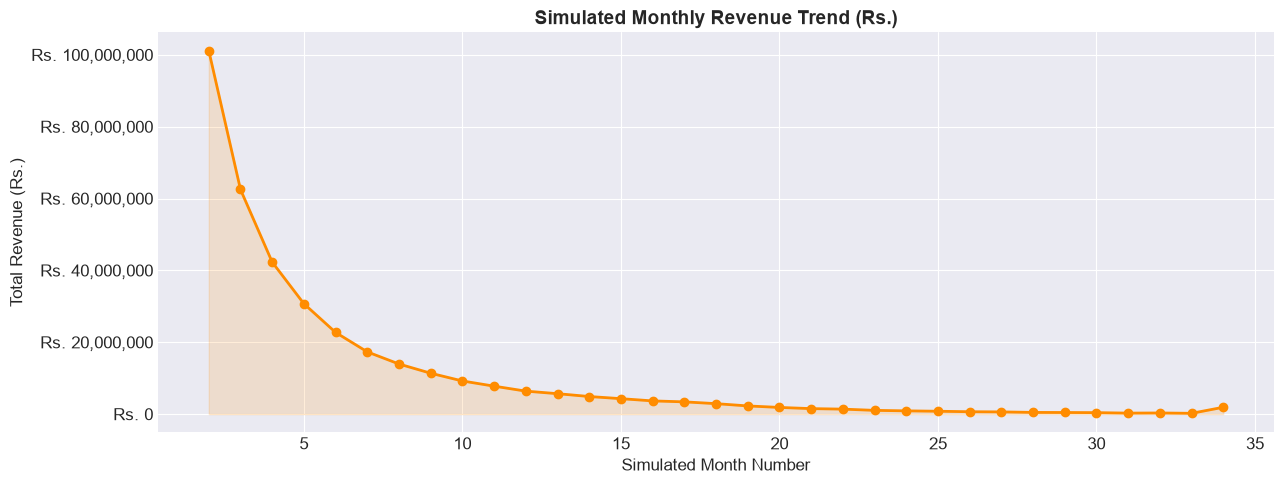

Revenue trend plot saved


In [16]:
# What: Plot monthly revenue trend to confirm data quality
# Why: Verify that engineered revenue is plausible and shows variation for modelling
# Method: Line chart of total_revenue per simulated month
plt.figure(figsize=(13, 5))
plt.plot(monthly_summary['month_num'], monthly_summary['total_revenue'],
         marker='o', color='darkorange', linewidth=2)
plt.fill_between(monthly_summary['month_num'], monthly_summary['total_revenue'], alpha=0.15, color='darkorange')
plt.title('Simulated Monthly Revenue Trend (Rs.)', fontsize=14, fontweight='bold')
plt.xlabel('Simulated Month Number')
plt.ylabel('Total Revenue (Rs.)')
plt.gca().yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'Rs. {x:,.0f}'))
plt.tight_layout()
plt.savefig('../models/eda_monthly_revenue.png', dpi=150, bbox_inches='tight')
plt.show()
print('Revenue trend plot saved')

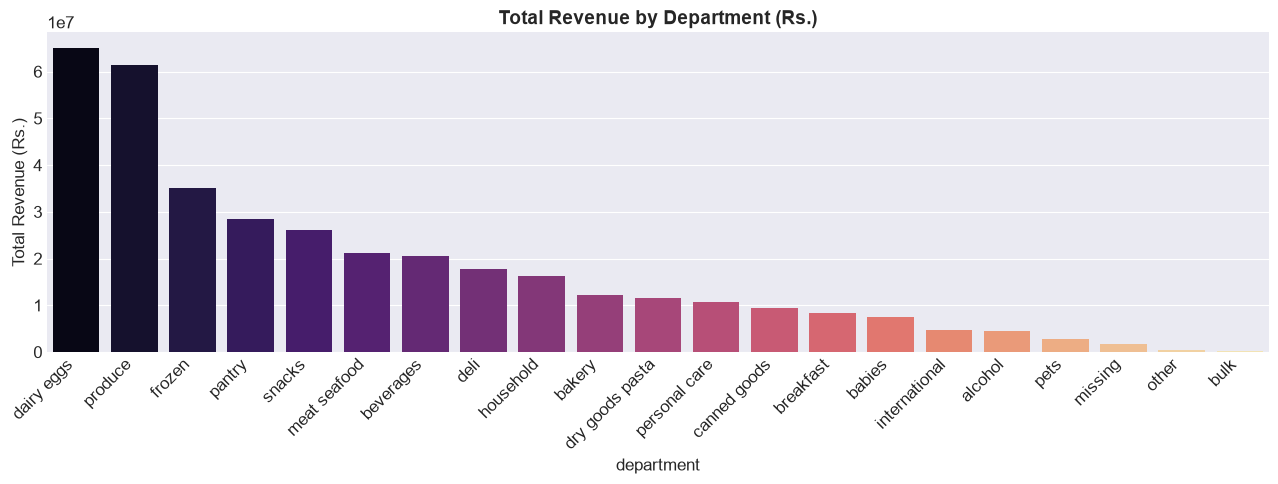


Top 5 departments by revenue:
    department   revenue
15  dairy eggs  65115300
3      produce  61363050
0       frozen  35149100
12      pantry  28434700
18      snacks  26149640


In [13]:
# What: Show top departments by total revenue
# Why: Useful context for category classification model
# Method: Merge department labels, group by department, sum revenue
dept_revenue = order_items.groupby('department_id')['revenue'].sum().reset_index()
dept_revenue = dept_revenue.merge(departments, on='department_id').sort_values('revenue', ascending=False)

plt.figure(figsize=(13, 5))
sns.barplot(data=dept_revenue, x='department', y='revenue', palette='magma')
plt.title('Total Revenue by Department (Rs.)', fontsize=14, fontweight='bold')
plt.xticks(rotation=45, ha='right')
plt.ylabel('Total Revenue (Rs.)')
plt.tight_layout()
plt.savefig('../models/eda_dept_revenue.png', dpi=150, bbox_inches='tight')
plt.show()
print('\nTop 5 departments by revenue:')
print(dept_revenue[['department','revenue']].head())

In [15]:
# What: Summary statistics for all model-relevant features
# Why: Final validation that data is clean and ready for modelling
# Method: pandas describe() on key numeric columns
print('Key feature statistics:')
print(order_items[['price','revenue','order_dow','order_hour_of_day','reordered']].describe().round(2))
print('\n Data exploration complete — proceed to model notebooks 01–06')

Key feature statistics:
            price     revenue   order_dow  order_hour_of_day   reordered
count  1384617.00  1384617.00  1384617.00         1384617.00  1384617.00
mean       264.10      264.10        2.70              13.58        0.60
std        121.61      121.61        2.17               4.24        0.49
min        150.00      150.00        0.00               0.00        0.00
25%        150.00      150.00        1.00              10.00        0.00
50%        220.00      220.00        3.00              14.00        1.00
75%        350.00      350.00        5.00              17.00        1.00
max        800.00      800.00        6.00              23.00        1.00

 Data exploration complete — proceed to model notebooks 01–06
